# How much run luck is left at temperature 0.2 and at temperature 0?

- This notebook measures the run-to-run luck of the 3 phase-1 models on
  HumanEval+ at lower temperatures, with both scaffolds
  - It is Study C of `preregistration_2.md`, whose design and predictions
    were committed before any phase-2 answer was scored
  - Each model got 3 runs at temperature 0.2 and a second greedy run
    (temperature 0), next to its 5 runs at 0.8 from phase 1
- The pedagogical arc:
  - The scores at the 3 temperatures
  - How much of the variance is run-to-run luck at 0.2
  - How often 2 greedy runs disagree
  - Whether the close pair can be told apart at 0.2
  - How stable a 1-run leaderboard is at 0.2 and at 0.8
  - Which predictions held

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as rutils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rutils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp40hnp4n3.json --HistoryManager.hist_file=:memory:


# Part 1: The scores at 3 temperatures

## Cell 1.1: Load the scores of both phases

- Phase 1 has 1 greedy run and 5 runs at 0.8; phase 2 adds 3 runs at 0.2 and
  a second greedy run
- The greedy files got their second run in phase 2 and were scored again, so
  their phase-2 scores replace the phase-1 ones

In [3]:
# Read the local scores of both phases and the settings of the analysis.
PHASE_1_DIR = "data/coding_runs"
PHASE_2_DIR = "data/coding_runs_phase2"
BENCHMARK = "humaneval"
LOW, HIGH = 0.2, 0.8
MODELS = list(rutils.PHASE_1_MODELS)
CLOSE_PAIR = ("codeqwen:7b-chat-v1.5-q4_K_M", "opencoder:8b")
old_scores = rutils.load_scores(PHASE_1_DIR, pattern="local_*.csv.gz")
new_scores = rutils.load_scores(PHASE_2_DIR)
scores = rutils.combine_scores(old_scores, new_scores)
study = scores[(scores["benchmark"] == BENCHMARK) & scores["model"].isin(MODELS)]

print("study.shape=", study.shape)
display(rutils.compute_score_table(study).round(3))
# Outcome: 9,840 rows, the 3 models x 2 scaffolds x 164 tasks with 2 greedy
# runs, 3 runs at 0.2, and 5 runs at 0.8. The one-shot plus scores, greedy /
# 0.2 / 0.8, are 78.7 / 80.1 / 74.1 for CodeQwen 7B, 79.3 / 78.0 / 72.7 for
# OpenCoder 8B, and 59.1 / 56.9 / 55.5 for DeepSeek-Coder 1.3B, so only
# CodeQwen does better at 0.2 than greedy.

study.shape= (9840, 19)


n_tasks  n_runs  base_pass  plus_pass  mean_attempts  mean_seconds
source benchmark model                               temperature scaffold                                                                    
local  humaneval codeqwen:7b-chat-v1.5-q4_K_M        0.0         one_shot      164       2      0.829      0.787          1.000        23.372
                                                                 repair        164       2      0.835      0.787          1.116        25.502
                                                     0.2         one_shot      164       3      0.841      0.801          1.000        18.428
                                                                 repair        164       3      0.848      0.803          1.091        19.844
                                                     0.8         one_shot      164       5      0.796      0.741          1.000        13.942
                                                                 repair        164       5      0.816      0.757          1.122        15.635
                 deepseek-coder:1.3b-instruct-q4_K_M 0.0         one_shot      164       2      0.628      0.591          1.000         2.566
                                                                 repair        164       2      0.628      0.591          1.195         3.262
                                                     0.2         one_shot      164       3      0.616      0.569          1.000         2.365
                                                                 repair        164       3      0.616      0.569          1.203         3.054
                                                     0.8         one_shot      164       5      0.595      0.555          1.000         2.147
                                                                 repair        164       5      0.604      0.563          1.239         2.902
                 opencoder:8b                        0.0         one_shot      164       2      0.835      0.793          1.000         9.044
                                                                 repair        164       2      0.829      0.787          1.067         9.532
                                                     0.2         one_shot      164       3      0.821      0.780          1.000         9.770
                                                                 repair        164       3      0.819      0.778          1.093        10.531
                                                     0.8         one_shot      164       5      0.773      0.727          1.000         8.544
                                                                 repair        164       5      0.776      0.728          1.118         9.469

## Cell 1.2: Checks of the scoring

- Every phase-2 answer is scored twice, so a flaky test shows up as an answer
  that passes once and fails once
- Not in the pre-registration: the run-0 greedy answers were scored in both
  phases, so they should get the same results

In [4]:
# Check the scoring of phase 2.
flaky_share = rutils.compute_flaky_share(new_scores)
agreement = rutils.compute_rescored_agreement(old_scores, new_scores)

print("flaky_share=", flaky_share)
print("agreement=", agreement)
# Outcome: 2 of the 17,928 phase-2 rows are flaky (0.011%), both in the greedy
# MBPP+ scores of DeepSeek-Coder 6.7B, and the 984 greedy answers of run 0,
# scored in both phases, got the same result both times.

flaky_share= 0.00011155734047300312
agreement= {'n_answers': 984, 'same_share': 1.0}


# Part 2: How much of the variance is run luck at 0.2?

## Cell 2.1: Task and run parts of the variance at 0.2 and at 0.8

- The run share at 0.2 comes from its 3 runs, and the one at 0.8 from the 5
  runs of phase 1
  - Both estimates are unbiased, whatever the number of runs

In [5]:
# Split the variance of every agent at the 2 temperatures.
variance = {
    temperature: rutils.compute_variance_table(
        study, source="local", benchmark=BENCHMARK, temperature=temperature
    )
    for temperature in (LOW, HIGH)
}

for temperature, table in variance.items():
    print("temperature=", temperature)
    display(table.round(4))
# Outcome: at 0.2 runs are 15% to 21% of the variance of 1 run, against 37% to
# 52% at 0.8, and the run variance is 1.9 to 3.1 times smaller. Part of the
# variance moves from the runs to the tasks, so the standard error of a 1-run
# score is 3.1 to 3.9 points at 0.2, against 3.4 to 3.9 at 0.8.

temperature= 0.2


,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
codeqwen 7b / repair,0.8028,0.1266,0.0325,0.2044,0.0311,0.0289
codeqwen 7b / one_shot,0.8008,0.1278,0.0325,0.2028,0.0313,0.0291
opencoder 8b / one_shot,0.7805,0.1458,0.0264,0.1534,0.0324,0.0307
opencoder 8b / repair,0.7785,0.1470,0.0264,0.1524,0.0325,0.0308
deepseek-coder 1.3b / one_shot,0.5691,0.1957,0.0508,0.2061,0.0388,0.0360
deepseek-coder 1.3b / repair,0.5691,0.1957,0.0508,0.2061,0.0388,0.0360


temperature= 0.8


,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
codeqwen 7b / repair,0.7573,0.0930,0.0915,0.4958,0.0335,0.0261
codeqwen 7b / one_shot,0.7415,0.0924,0.1000,0.5198,0.0342,0.0262
opencoder 8b / repair,0.7280,0.1238,0.0750,0.3772,0.0348,0.0291
opencoder 8b / one_shot,0.7268,0.1256,0.0738,0.3700,0.0349,0.0293
deepseek-coder 1.3b / repair,0.5634,0.1488,0.0982,0.3974,0.0388,0.0321
deepseek-coder 1.3b / one_shot,0.5549,0.1449,0.1030,0.4155,0.0389,0.0318


## Cell 2.2: Plot of the 2 parts at 0.2

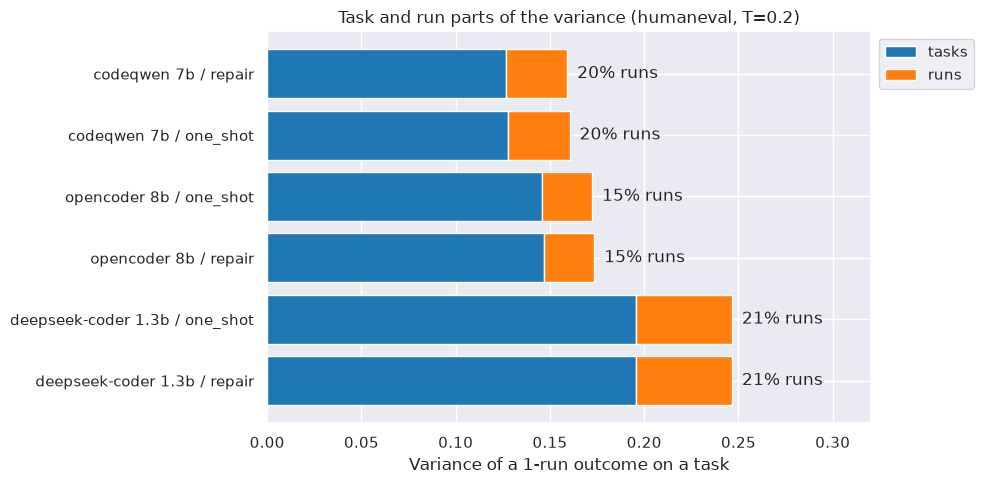

In [6]:
# Plot the task part and the run part of every agent at 0.2.
rutils.plot_variance_parts(
    variance[LOW],
    title=f"Task and run parts of the variance ({BENCHMARK}, T={LOW:g})",
    figsize=(10, 5),
)
# Outcome: the run part is a thin slice of every bar at 0.2, and DeepSeek-Coder
# 1.3B has the largest total because its score is the closest to 50%.

# Part 3: Do 2 greedy runs agree?

## Cell 3.1: Tasks that change between the 2 greedy runs

- Greedy decoding has no randomness, so a task can only change through
  Ollama itself, e.g., its prompt cache

In [7]:
# Count the tasks whose one-shot result changes between the greedy runs.
greedy_changes = rutils.compute_greedy_changes(
    study, models=MODELS, benchmark=BENCHMARK
)

display(greedy_changes.round(4))
# Outcome: none of the 164 one-shot results changes between the 2 greedy runs,
# for any of the 3 models, so a greedy rerun gives the same score.

,n_tasks,n_changed,changed_share,score_run_0,score_run_1
deepseek-coder:1.3b-instruct-q4_K_M,164,0,0.0,0.5915,0.5915
codeqwen:7b-chat-v1.5-q4_K_M,164,0,0.0,0.7866,0.7866
opencoder:8b,164,0,0.0,0.7927,0.7927


# Part 4: Can the close pair be told apart at 0.2?

## Cell 4.1: Paired comparisons of the close pair

- CodeQwen 7B against OpenCoder 8B, 1 test per scaffold, over the tasks and
  the 3 runs at 0.2
- The Holm adjustment covers the 2 tests

In [8]:
# Compare the close pair at 0.2, for each scaffold.
pairs = [
    ((CLOSE_PAIR[0], scaffold), (CLOSE_PAIR[1], scaffold))
    for scaffold in ("one_shot", "repair")
]
comparisons = rutils.compare_agent_pairs(
    study, pairs, source="local", benchmarks=[BENCHMARK], temperature=LOW
)

display(comparisons.round(4))
# Outcome: at 0.2 CodeQwen 7B is 2.0 points above OpenCoder 8B with one-shot
# and 2.4 points with repair, with 95% intervals of -3.9 to +7.5 and -3.5 to
# +7.9 points and a Holm p of 0.79 for both, so the pair still cannot be told
# apart.

,benchmark,agent_a,agent_b,gap,ci_low,ci_high,gap_run_0,p_value,p_holm,distinguishable
0,humaneval,codeqwen 7b / one_shot,opencoder 8b / one_shot,0.0203,-0.0386,0.0752,0.0427,0.4722,0.786,False
1,humaneval,codeqwen 7b / repair,opencoder 8b / repair,0.0244,-0.0346,0.0793,0.0427,0.3930,0.786,False


# Part 5: How stable is a 1-run leaderboard at 0.2?

## Cell 5.1: Order of the 3 models in random 1-run leaderboards

- For each scaffold, a 1-run leaderboard picks 1 run per model
  - Every combination of runs is taken once (3^3 = 27), so the shares are
    exact instead of coming from random draws, which could split 2 equal
    shares by chance
- At 0.8 only the first 3 runs are used, as at 0.2: with fewer runs, the drawn
  run is a bigger part of the mean it is checked against

In [9]:
# Draw random 1-run leaderboards of the 3 models from their first 3 runs.
stability = rutils.compute_stability_table(
    study,
    models=MODELS,
    benchmark=BENCHMARK,
    temperatures=[LOW, HIGH],
    n_runs=3,
)

display(stability.round(3))
# Outcome: with 3 runs per model there are only 27 leaderboards per scaffold.
# With one-shot, 24 of the 27 keep the order at both temperatures; with repair,
# 24 at 0.2 and 18 at 0.8. The mean Kendall tau is higher at 0.2 with both
# scaffolds (0.91 against 0.87 and 0.78).

p_same_order  mean_kendall_tau
scaffold temperature                                
one_shot 0.2                 0.889             0.906
         0.8                 0.889             0.865
repair   0.2                 0.889             0.906
         0.8                 0.667             0.778

# Part 6: Which predictions held?

## Cell 6.1: Predictions against the results

- The rules follow `preregistration_2.md`, which was committed before any
  phase-2 answer was scored

In [10]:
# Check each prediction of Study C.
predictions = rutils.check_temperature_predictions(
    variance_low=variance[LOW],
    variance_high=variance[HIGH],
    greedy_changes=greedy_changes,
    comparisons=comparisons,
    stability=stability,
    low=LOW,
    high=HIGH,
)

display(predictions)
# Outcome: C1 to C4 hold and C5 does not: with one-shot, 1-run leaderboards
# keep the order exactly as often at 0.2 as at 0.8 (88.9%), and only with
# repair are they more stable at 0.2 (88.9% against 66.7%).

,prediction,observed,holds
C1,Runs are 5% to 30% of the variance at 0.2,"6 of 6 inside, from 15% to 21%",True
C2,The run share is lower at 0.2 than at 0.8,"6 of 6 lower, by 19 to 32 points",True
C3,Fewer than 2% of the tasks change between gree...,"3 of 3 models below 2%, from 0.0% to 0.0%",True
C4,The close pair is not distinguishable at 0.2,"0 of 2 comparisons distinguishable, smallest H...",True
C5,1-run leaderboards keep the order more often a...,1 of 2 scaffolds more often (one_shot 88.9% vs...,False


# Part 7: Takeaways

- Going from temperature 0.8 to 0.2 cuts run luck from 37% to 52% of the
  variance of 1 run down to 15% to 21%, and 2 greedy runs give the same
  result on every task
- A 1-run score is only a little more precise at 0.2: part of the variance
  moves from the runs to the tasks, so its standard error is 3.1 to 3.9
  points against 3.4 to 3.9 at 0.8
- The close pair stays too close to call at 0.2, and its order depends on the
  temperature: OpenCoder 8B is ahead in the greedy one-shot runs (79.3
  against 78.7) and CodeQwen 7B at 0.2 and 0.8
- Prediction C5 missed with the one-shot scaffold, by a tie: 24 of the 27
  1-run leaderboards keep the order at both temperatures